In [3]:
import pandas as pd
import csv

rows = []

with open(file_path, "r", newline="", encoding="utf-8-sig") as file:
    reader = csv.reader(file)
    header = next(reader)

    # Remove unnecessary spaces from column names
    columns = [name.strip() for name in header]

    for row in reader:
        row = [value.strip() for value in row]

        # Reconstruct the two coordinate fields
        rows.append([
            row[0],                  # Order_ID
            row[1] + ", " + row[2],  # Customer_Location
            row[3] + ", " + row[4],  # Restaurant_Location
            *row[5:]                 # Remaining columns
        ])

df = pd.DataFrame(rows, columns=columns)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst row:")
print(df.iloc[0].to_string())

Dataset shape: (200, 15)

Column names:
['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance', 'Weather_Conditions', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Order_Time', 'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time', 'Order_Cost', 'Tip_Amount']

First row:
Order_ID                                       ORD0001
Customer_Location             "(17.030479, 79.743077)"
Restaurant_Location           "(12.358515, 85.100083)"
Distance                                          1.57
Weather_Conditions                               Rainy
Traffic_Conditions                              Medium
Delivery_Person_Experience                           4
Order_Priority                                  Medium
Order_Time                                   Afternoon
Vehicle_Type                                       Car
Restaurant_Rating                                  4.1
Customer_Rating                                      3
Delivery_Tim

In [5]:
print("Dataset shape:", df.shape)

print("\n--- Data types ---")
print(df.dtypes)

print("\n--- Missing values per column ---")
print(df.isnull().sum())

print("\n--- Duplicate rows ---")
print(df.duplicated().sum())

print("\n--- Unique values in categorical columns ---")
categorical_columns = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())

Dataset shape: (200, 15)

--- Data types ---
Order_ID                      object
Customer_Location             object
Restaurant_Location           object
Distance                      object
Weather_Conditions            object
Traffic_Conditions            object
Delivery_Person_Experience    object
Order_Priority                object
Order_Time                    object
Vehicle_Type                  object
Restaurant_Rating             object
Customer_Rating               object
Delivery_Time                 object
Order_Cost                    object
Tip_Amount                    object
dtype: object

--- Missing values per column ---
Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0

In [7]:
numeric_columns = [
    "Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Delivery_Time",
    "Order_Cost",
    "Tip_Amount"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="raise")

print("--- Updated data types ---")
print(df.dtypes)

print("\n--- Numeric summary ---")
print(df[numeric_columns].describe())

--- Updated data types ---
Order_ID                       object
Customer_Location              object
Restaurant_Location            object
Distance                      float64
Weather_Conditions             object
Traffic_Conditions             object
Delivery_Person_Experience      int64
Order_Priority                 object
Order_Time                     object
Vehicle_Type                   object
Restaurant_Rating             float64
Customer_Rating               float64
Delivery_Time                 float64
Order_Cost                    float64
Tip_Amount                    float64
dtype: object

--- Numeric summary ---
         Distance  Delivery_Person_Experience  Restaurant_Rating  \
count  200.000000                  200.000000         200.000000   
mean    11.498050                    5.250000           3.738500   
std      6.841755                    2.745027           0.703021   
min      0.520000                    1.000000           2.500000   
25%      6.090000       

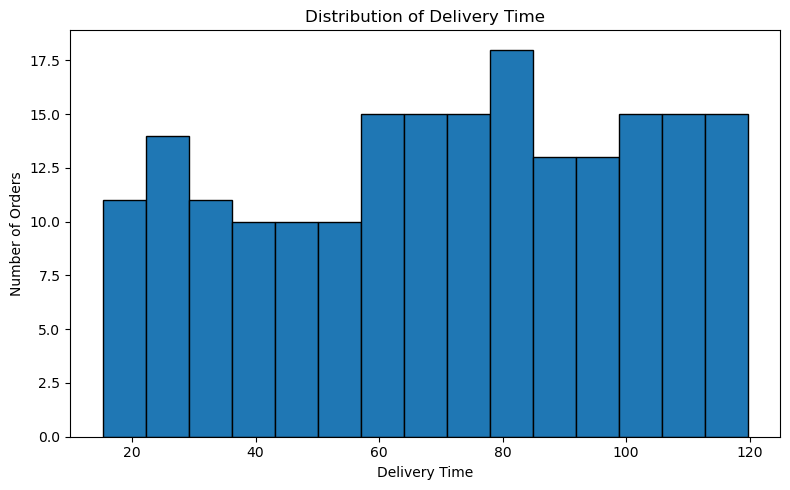

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Delivery_Time"], bins=15, edgecolor="black")

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

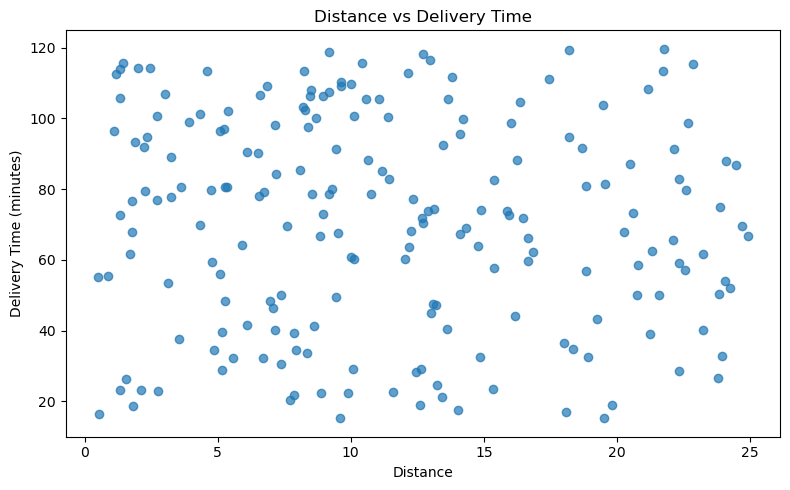

Correlation: -0.07514271018515736


In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Distance"], df["Delivery_Time"], alpha=0.7)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

print(
    "Correlation:",
    df["Distance"].corr(df["Delivery_Time"])
)

<Figure size 800x500 with 0 Axes>

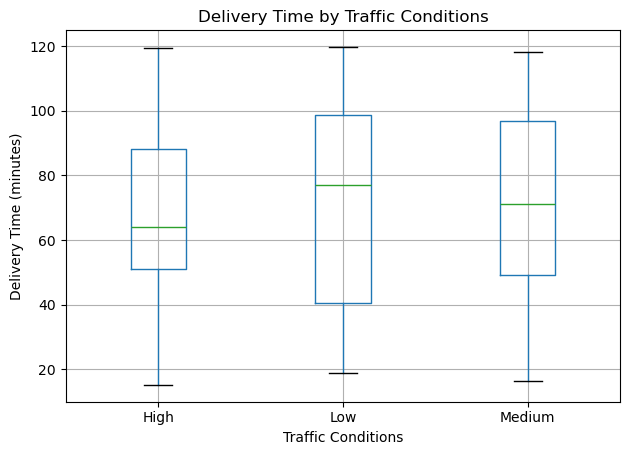

In [14]:
plt.figure(figsize=(8, 5))

df.boxplot(column="Delivery_Time", by="Traffic_Conditions")

plt.title("Delivery Time by Traffic Conditions")
plt.suptitle("")
plt.xlabel("Traffic Conditions")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

                    count   mean  median    std
Weather_Conditions                             
Cloudy                 42  69.79   68.20  31.23
Rainy                  57  73.06   79.09  30.77
Snowy                  48  69.19   72.28  28.01
Sunny                  53  69.48   72.91  29.96


<Figure size 800x500 with 0 Axes>

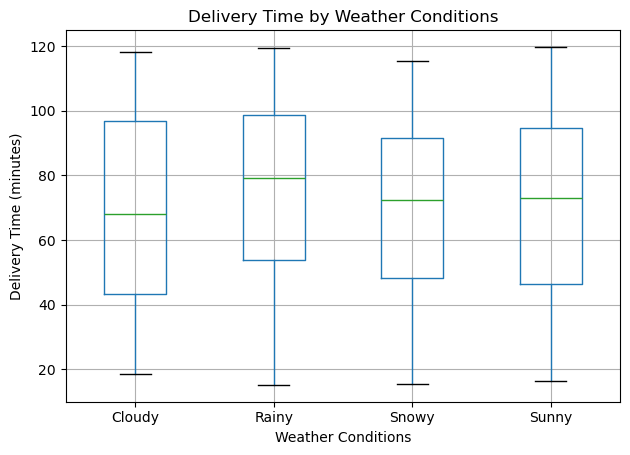

In [17]:
print(
    df.groupby("Weather_Conditions")["Delivery_Time"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)

plt.figure(figsize=(8, 5))

df.boxplot(column="Delivery_Time", by="Weather_Conditions")

plt.title("Delivery Time by Weather Conditions")
plt.suptitle("")
plt.xlabel("Weather Conditions")
plt.ylabel("Delivery Time (minutes)")

plt.tight_layout()
plt.show()

                            Distance  Delivery_Person_Experience  \
Distance                        1.00                        0.02   
Delivery_Person_Experience      0.02                        1.00   
Restaurant_Rating               0.06                       -0.00   
Customer_Rating                 0.00                       -0.12   
Delivery_Time                  -0.08                       -0.02   
Order_Cost                     -0.02                        0.06   
Tip_Amount                     -0.01                       -0.07   

                            Restaurant_Rating  Customer_Rating  Delivery_Time  \
Distance                                 0.06             0.00          -0.08   
Delivery_Person_Experience              -0.00            -0.12          -0.02   
Restaurant_Rating                        1.00             0.10          -0.09   
Customer_Rating                          0.10             1.00          -0.02   
Delivery_Time                           -0.09     

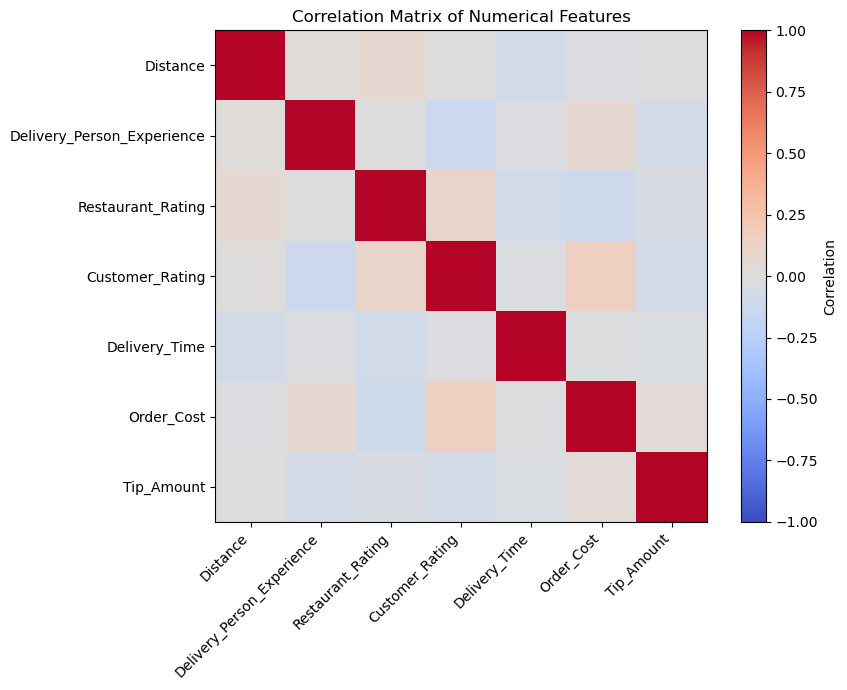

In [20]:
numeric_columns = [
    "Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Delivery_Time",
    "Order_Cost",
    "Tip_Amount"
]

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numeric_columns)),
    numeric_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(numeric_columns)), numeric_columns)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [21]:
#The correlation matrix indicates that there are virtually no strong linear relationships between the numerical features and `Delivery_Time`. All correlations with the target are close to zero, ranging from -0.09 to -0.01. The correlations among the numerical features are also generally weak, suggesting little linear association between them. However, weak correlation does not necessarily mean that a feature has no predictive value, as nonlinear relationships or interactions between features may still exist.

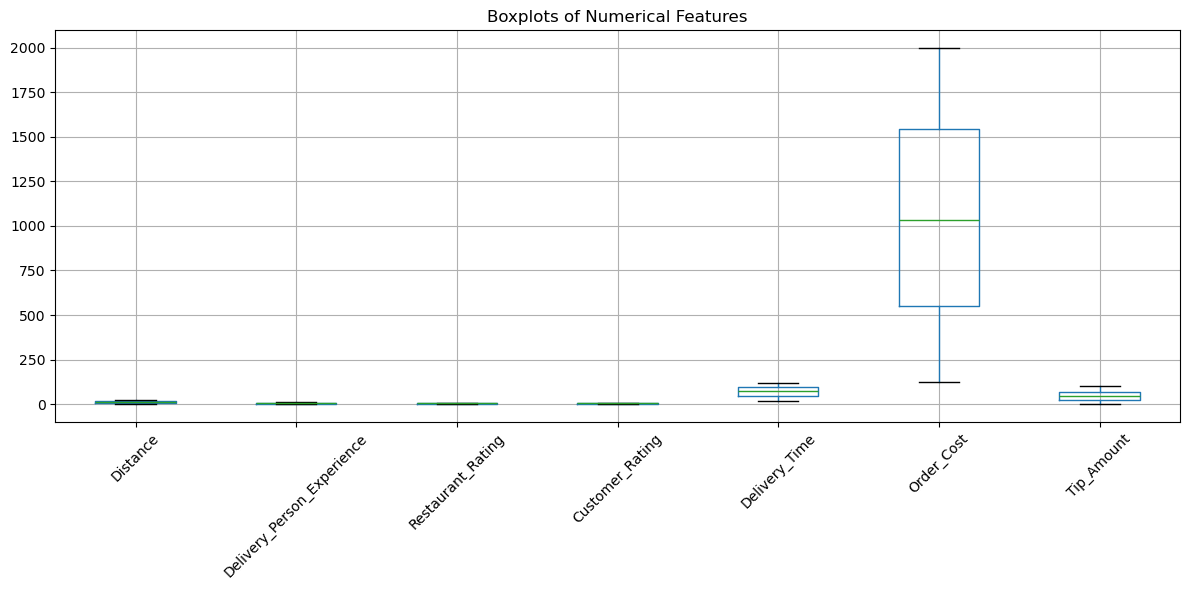

In [23]:
numeric_columns = [
    "Distance",
    "Delivery_Person_Experience",
    "Restaurant_Rating",
    "Customer_Rating",
    "Delivery_Time",
    "Order_Cost",
    "Tip_Amount"
]

plt.figure(figsize=(12, 6))
df[numeric_columns].boxplot(rot=45)
plt.title("Boxplots of Numerical Features")
plt.tight_layout()
plt.show()

In [24]:
#The boxplots illustrate the distribution, median, and spread of the numerical features. `Order_Cost` has a substantially larger numerical scale than the other variables. No obvious extreme outliers were observed beyond the whiskers. However, potential outliers should be evaluated in context rather than automatically removed.

In [26]:
X = df.drop(columns=[
    "Order_ID",
    "Customer_Location",
    "Restaurant_Location",
    "Delivery_Time",
    "Customer_Rating",
    "Restaurant_Rating"
])

y = df["Delivery_Time"]

print("X shape: ", X.shape)
print("y shape: ", y.shape)

print("\nFeatures: ")
print(X.columns.tolist())

X shape:  (200, 9)
y shape:  (200,)

Features: 
['Distance', 'Weather_Conditions', 'Traffic_Conditions', 'Delivery_Person_Experience', 'Order_Priority', 'Order_Time', 'Vehicle_Type', 'Order_Cost', 'Tip_Amount']


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (160, 9)
X_test: (40, 9)
y_train: (160,)
y_test: (40,)


In [30]:
numerical_columns = [
    "Distance",
    "Delivery_Person_Experience",
    "Order_Cost",
    "Tip_Amount"
]

categorical_columns = [
    "Weather_Conditions",
    "Traffic_Conditions",
    "Order_Priority",
    "Order_Time",
    "Vehicle_Type"
]

print("Numerical features:", len(numerical_columns))
print("Categorical features:", len(categorical_columns))

Numerical features: 4
Categorical features: 5


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Data:", X_train_processed.shape)
print("Processed Testing Data:", X_test_processed.shape)

Processed Training Data: (160, 21)
Processed Testing Data: (40, 21)


In [36]:
print("Processed training data type:", type(X_train_processed))
print("Number of transformed features:", X_train_processed.shape[1])

print("\nFirst 5 processed rows:")
print(X_train_processed[:5])

Processed training data type: <class 'numpy.ndarray'>
Number of transformed features: 21

First 5 processed rows:
[[ 1.87620817  0.58647223 -0.02288968  1.32344966  0.          0.
   1.          0.          1.          0.          0.          1.
   0.          0.          1.          0.          0.          0.
   1.          0.          0.        ]
 [ 1.34498016 -0.50888446  0.56557139 -1.41295305  0.          0.
   1.          0.          1.          0.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.          1.          0.        ]
 [-0.957493    1.31671002 -1.08064877 -1.4232908   0.          0.
   0.          1.          0.          1.          0.          0.
   0.          1.          1.          0.          0.          0.
   0.          0.          1.        ]
 [-0.04494516 -0.14376557  1.52349019 -0.84299837  0.          0.
   0.          1.          0.          0.          1.          0.
   0.          1.          0.          1.  

In [39]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_processed, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("R² Score:", round(r2, 3))

Mean Absolute Error (MAE): 27.42
Mean Squared Error (MSE): 1042.1
R² Score: -0.127


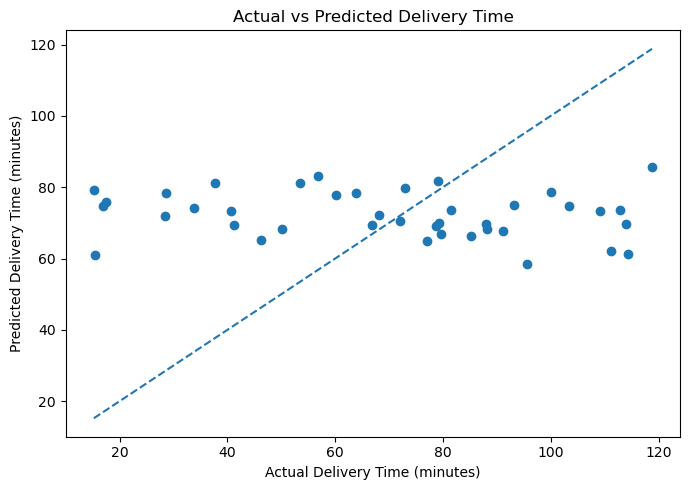

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.tight_layout()
plt.show()

In [47]:
threshold = y.median()

print("Median Delivery Time:", round(threshold, 2), "minutes")

Median Delivery Time: 72.78 minutes


In [49]:
import numpy as np

y_class = np.where(y <= threshold, 0, 1)

print("Class labels: 0 = Fast, 1 = Delayed")
print("\nClass distribution:")
print("Fast:", (y_class == 0).sum())
print("Delayed:", (y_class == 1).sum())

Class labels: 0 = Fast, 1 = Delayed

Class distribution:
Fast: 100
Delayed: 100


In [51]:
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X, y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Training data:", X_train_cls.shape)
print("Testing data:", X_test_cls.shape)

print("\nTraining class distribution:")
print("Fast:", (y_train_cls == 0).sum())
print("Delayed:", (y_train_cls == 1).sum())

print("\nTesting class distribution:")
print("Fast:", (y_test_cls == 0).sum())
print("Delayed:", (y_test_cls == 1).sum())

Training data: (160, 9)
Testing data: (40, 9)

Training class distribution:
Fast: 80
Delayed: 80

Testing class distribution:
Fast: 20
Delayed: 20


In [53]:
X_train_cls_processed = preprocessor.fit_transform(X_train_cls)
X_test_cls_processed = preprocessor.transform(X_test_cls)

print("Processed Training Data:", X_train_cls_processed.shape)
print("Processed Testing Data:", X_test_cls_processed.shape)

Processed Training Data: (160, 21)
Processed Testing Data: (40, 21)


In [55]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(max_iter=1000)

classifier.fit(X_train_cls_processed, y_train_cls)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [57]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_cls = classifier.predict(X_test_cls_processed)

print("Accuracy:", round(accuracy_score(y_test_cls, y_pred_cls), 3))

print("\nClassification Report:")
print(classification_report(
    y_test_cls,
    y_pred_cls,
    target_names=["Fast", "Delayed"]
))

Accuracy: 0.425

Classification Report:
              precision    recall  f1-score   support

        Fast       0.42      0.40      0.41        20
     Delayed       0.43      0.45      0.44        20

    accuracy                           0.42        40
   macro avg       0.42      0.43      0.42        40
weighted avg       0.42      0.42      0.42        40



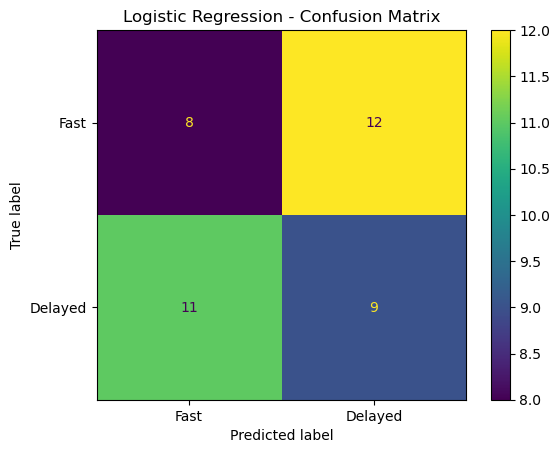

[[ 8 12]
 [11  9]]


In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_cls, y_pred_cls, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fast", "Delayed"]
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

print(cm)

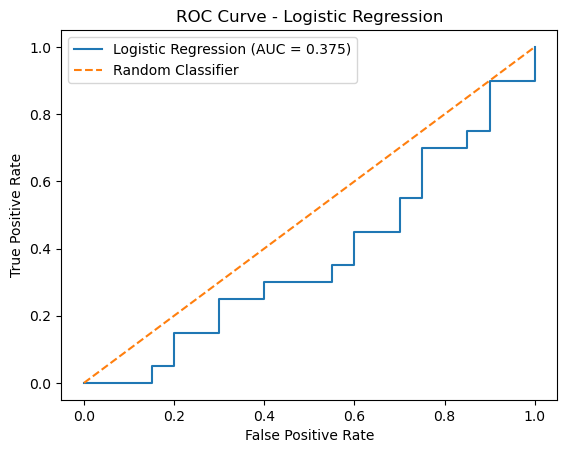

AUC: 0.375


In [61]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = classifier.predict_proba(X_test_cls_processed)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_cls, y_prob)
auc_score = roc_auc_score(y_test_cls, y_prob)

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print("AUC:", round(auc_score, 3))

In [63]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

baseline_cls = DummyClassifier(strategy="most_frequent")
baseline_cls.fit(X_train_cls_processed, y_train_cls)

baseline_pred = baseline_cls.predict(X_test_cls_processed)
baseline_prob = baseline_cls.predict_proba(X_test_cls_processed)[:, 1]

print("Baseline Accuracy:", round(accuracy_score(y_test_cls, baseline_pred), 3))
print("Baseline AUC:", round(roc_auc_score(y_test_cls, baseline_prob), 3))

Baseline Accuracy: 0.5
Baseline AUC: 0.5


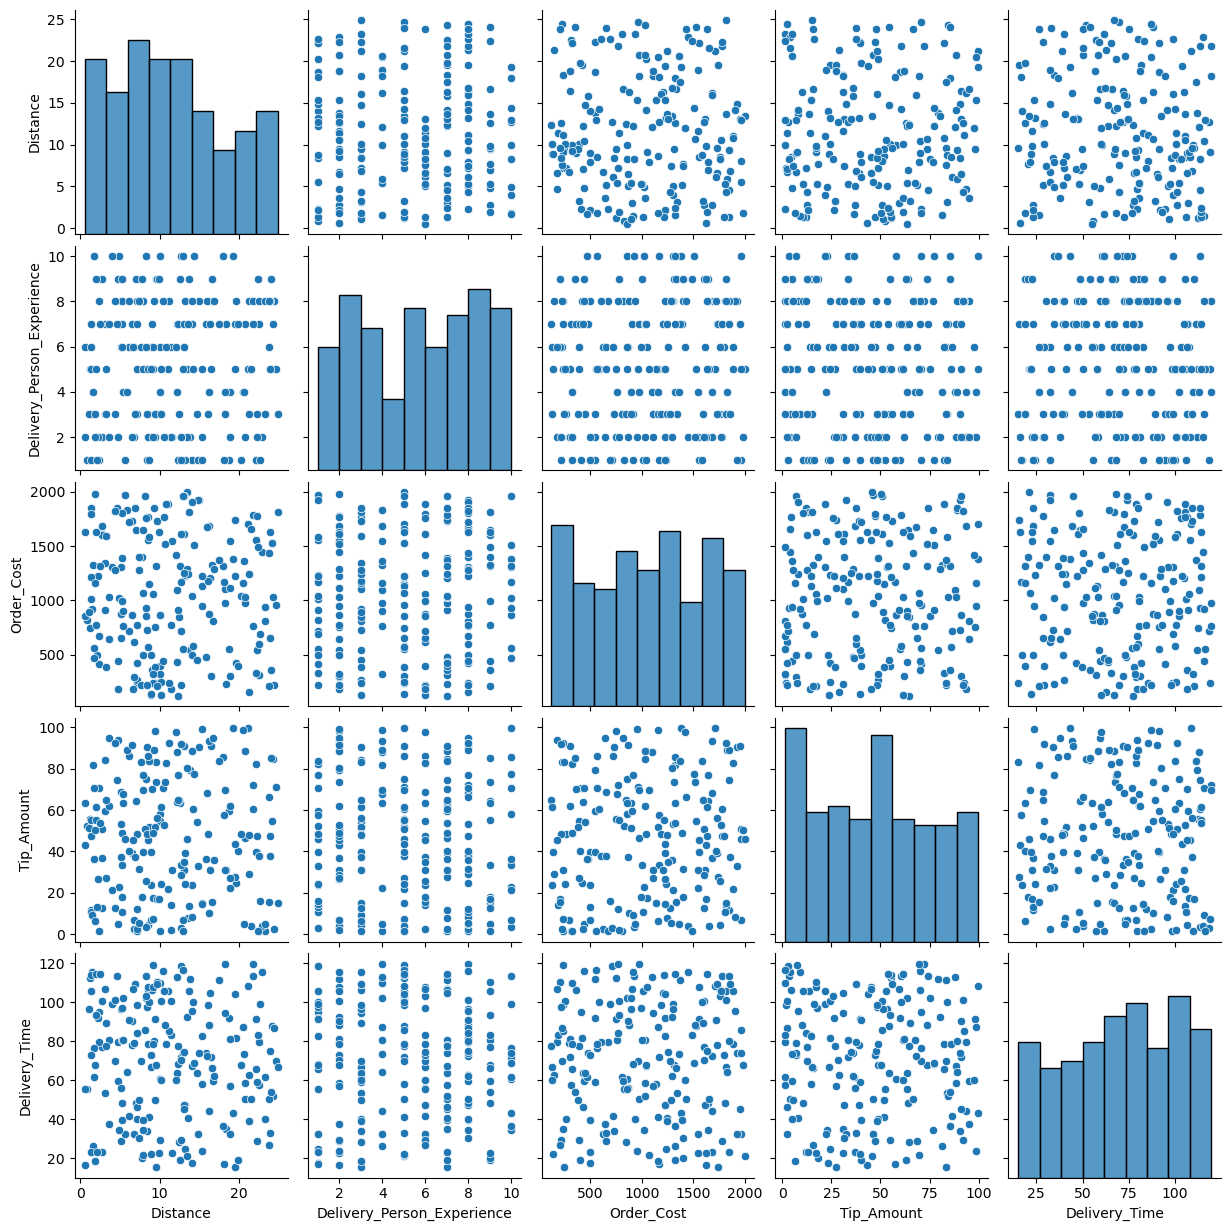

In [66]:
import seaborn as sns
import matplotlib.pyplot as plt

pairplot_columns = [
    "Distance",
    "Delivery_Person_Experience",
    "Order_Cost",
    "Tip_Amount",
    "Delivery_Time"
]

sns.pairplot(df[pairplot_columns], diag_kind="hist")
plt.show()

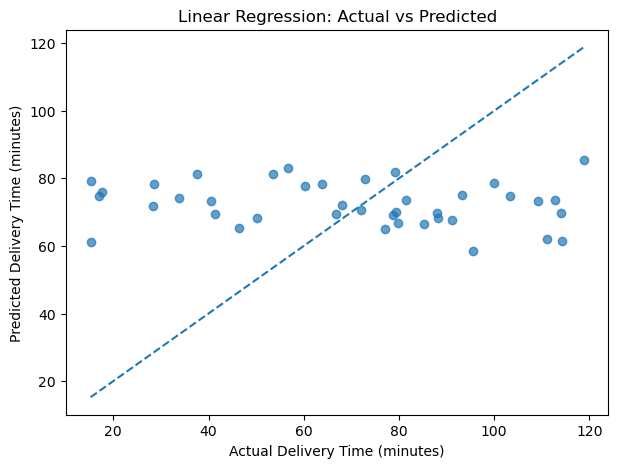

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [71]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Mean Baseline",
        "Logistic Regression",
        "Classification Baseline"
    ],
    "Task": [
        "Delivery Time Prediction",
        "Delivery Time Prediction",
        "Fast/Delayed Classification",
        "Fast/Delayed Classification"
    ],
    "MAE (minutes)": [
        27.42,
        25.53,
        None,
        None
    ],
    "Accuracy": [
        None,
        None,
        0.425,
        0.500
    ],
    "ROC-AUC": [
        None,
        None,
        0.375,
        0.500
    ]
})

print(model_comparison.to_string(index=False))

                  Model                        Task  MAE (minutes)  Accuracy  ROC-AUC
      Linear Regression    Delivery Time Prediction          27.42       NaN      NaN
          Mean Baseline    Delivery Time Prediction          25.53       NaN      NaN
    Logistic Regression Fast/Delayed Classification            NaN     0.425    0.375
Classification Baseline Fast/Delayed Classification            NaN     0.500    0.500
